# 12 Augmentation families and the effect of class balancing

Two earlier findings do not fit together comfortably. In this project's earlier experiments, augmentation
gave large improvements; in the rebuilt pipeline it gives almost none on top 1. Notebook 10 showed that
making the current bundle stronger does not help, but that only tested more of the same augmentations.
It did not test different kinds, and it did not separate augmentation from class balancing.

**Two things this notebook separates.**

1. *Class balancing vs augmentation.* The `none` condition in notebooks 06, 09 and 11 still uses the class
   balanced sampler, which oversamples rare classes by duplicating clips. So the measured benefit of
   augmentation is only the benefit on top of balancing. An older setup that generated augmented clips to
   build every class up to a fixed size, compared against an unbalanced no augmentation baseline, would
   credit augmentation with the whole balancing effect as well. Here the natural class frequency baseline
   (`none_natural`) is added so the two contributions can be read off separately.
2. *Which family of augmentation.* The current `advanced` bundle (limb rotation, confidence scaled noise,
   joint masking, temporal warp) is made of small local perturbations. The `basic` family (whole skeleton
   rotation, scaling, jitter, horizontal mirror, temporal crop) was never compared against it in the repaired
   pipeline, and it contains the two operations Li et al. (2024) list that can apply to skeleton data
   (cropping and horizontal flipping). Two notes on it: scaling is almost entirely cancelled by the body
   height normalisation, and horizontal mirroring changes handedness, which is a physically valid variation
   for badminton players.

**Configurations** (all ST-GCN, `body_court`, tuned recipe, validation only, tuning seeds 55 and 66):

| name | augmentation | class balancing |
|---|---|---|
| `none_natural` | none | none (natural class frequencies) |
| `none_balanced` | none | sampler (300 per class) |
| `basic` | basic family | sampler |
| `advanced` | current bundle | sampler |
| `basic_plus_advanced` | both families | sampler |

**Reading the table.** `none_balanced` minus `none_natural` is the effect of balancing alone. `advanced`
minus `none_balanced` is the effect of the current augmentation on top of balancing; the same for `basic`.

**Selection rule, fixed before running.** Among the four sampler configurations, a configuration replaces
`advanced` only if its mean validation top 1 is at least 0.5 points higher and its MCA is not more than 1
point lower. Test is never evaluated here. If nothing replaces `advanced`, notebooks 06, 09 and 11 stand.

Logs to `BadmintonPoseAnalysis/experiments/augmentation_families`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/augmentation_families"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs") + "/experiments/augmentation_families"
os.makedirs(OUT, exist_ok=True)

SEEDS = [55, 66]
SPLITS = ("train", "val")
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)

ds.AUGMENTATION_POLICIES["basic_plus_advanced"] = list(ds.BASIC_AUGMENTATIONS) + list(ds.ADVANCED_AUGMENTATIONS)

CONFIGS = {
    "none_natural": {"policy": "none", "balanced": False},
    "none_balanced": {"policy": "none", "balanced": True},
    "basic": {"policy": "basic", "balanced": True},
    "advanced": {"policy": "advanced", "balanced": True},
    "basic_plus_advanced": {"policy": "basic_plus_advanced", "balanced": True},
}
CURRENT = "advanced"
MIN_GAIN, MAX_MCA_DROP = 0.005, 0.01
print("recipe:", RECIPE)

recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
forward = stgcn_model.make_forward(USE_COURT)
in_channels = 7 if USE_COURT else 5

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Smoke test

Checks that each family perturbs the clips by a visible, plausible amount, that the natural frequency loader
really does iterate once over the training set while the balanced one draws more, and that one training
step runs on each policy.

In [4]:
train = manifest[manifest["split"] == "train"].reset_index(drop=True)
row = train.sample(1, random_state=0).iloc[0]
stem = os.path.splitext(os.path.basename(row["filepath"]))[0]
clip = np.load(f"{KEYPOINTS}/{row['class_name']}/{stem}.npy").astype(np.float32)
ref = ds.normalise_body(clip)[..., :2]

for name in ["none", "basic", "advanced", "basic_plus_advanced"]:
    shifts = []
    for _ in range(100):
        out = clip.copy()
        for fn in ds.AUGMENTATION_POLICIES[name]:
            out = fn(out)
        shifts.append(np.abs(ds.normalise_body(out)[..., :2] - ref).mean())
    print(f"{name:20s} mean change after body normalisation (body heights): {np.mean(shifts):.4f}")

tr.seed_everything(0)
for balanced in (True, False):
    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, "basic", NORMALISATION, seed=0,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=2, eval_workers=2, balanced=balanced)
    draws = len(loaders["train"].sampler) if balanced else len(loaders["train"].dataset)
    print(f"balanced={balanced}: {len(loaders['train'].dataset)} training clips, {draws} draws per epoch")
    model = stgcn_model.build_stgcn(in_channels, len(class_names)).to(device)
    batch = next(iter(loaders["train"]))
    nn.CrossEntropyLoss()(forward(model, batch, device), batch["label"].to(device)).backward()
    del model, loaders
print("smoke test passed")

none                 mean change after body normalisation (body heights): 0.0000
basic                mean change after body normalisation (body heights): 0.1296
advanced             mean change after body normalisation (body heights): 0.0102
basic_plus_advanced  mean change after body normalisation (body heights): 0.1503
balanced=True: 6247 training clips, 7948 draws per epoch
balanced=False: 6247 training clips, 6247 draws per epoch
smoke test passed


## Runs

Five configurations on two seeds: ten runs. Results are appended after every run and finished runs are
skipped.

In [5]:
results_path = f"{OUT}/results.csv"


def load_results():
    return pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])


def run_config(name, seed):
    done = load_results()
    if ((done["config"] == name) & (done["seed"] == seed)).any():
        print(f"skip {name} seed {seed}, already done")
        return
    cfg = CONFIGS[name]
    run_name = f"stgcn_augfam_{name}_s{seed}"
    print(f"\n=== {run_name}  {cfg} ===")
    tr.seed_everything(seed)

    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["aug_families", name, "stgcn", f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, **cfg, "config": name, "seed": seed, "keypoints": KEYPOINTS,
                  "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})

    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, cfg["policy"], NORMALISATION, seed=seed,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS, balanced=cfg["balanced"])
    model = stgcn_model.build_stgcn(in_channels, len(class_names)).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"config": name, "seed": seed})
    task.close()

    pd.concat([done, pd.DataFrame([metrics])], ignore_index=True).to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


for name in CONFIGS:
    for seed in SEEDS:
        run_config(name, seed)


=== stgcn_augfam_none_natural_s55  {'policy': 'none', 'balanced': False} ===
ClearML Task: created new task id=325c59baf8eb4e70bdcae7abafaf6201
2026-10-06 03:57:00,090 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/3f71cbe7f93546afa4b6877420cca96f/tasks/325c59baf8eb4e70bdcae7abafaf6201/output/log
epoch   0  loss 1.845  train 0.572  val 0.575 (mca 0.409)  *
epoch   1  loss 1.406  train 0.613  val 0.618 (mca 0.431)  *
epoch   2  loss 1.279  train 0.654  val 0.644 (mca 0.472)  *
epoch   4  loss 1.173  train 0.686  val 0.661 (mca 0.503)  *
epoch   5  loss 1.137  train 0.657  val 0.645 (mca 0.498)
epoch   7  loss 1.098  train 0.702  val 0.680 (mca 0.510)  *
epoch   8  loss 1.090  train 0.719  val 0.707 (mca 0.549)  *
epoch  10  loss 0.906  train 0.773  val 0.730 (mca 0.574)  *
epoch  12  loss 0.797  train 0.790  val 0.738 (mca 0.600)  *
epoch  15  loss 0.727  train 0.825  val 0.721 (mca 0.597)
epoch 

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  7.29MB/s]: 



=== stgcn_augfam_none_natural_s66  {'policy': 'none', 'balanced': False} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=0e694e0bd6cd48edbca28ceee7477103
ClearML results page: https://app.clear.ml/projects/3f71cbe7f93546afa4b6877420cca96f/tasks/0e694e0bd6cd48edbca28ceee7477103/output/log
epoch   0  loss 1.879  train 0.564  val 0.581 (mca 0.425)  *
epoch   1  loss 1.438  train 0.616  val 0.601 (mca 0.409)  *
epoch   2  loss 1.296  train 0.661  val 0.650 (mca 0.426)  *
epoch   3  loss 1.224  train 0.686  val 0.673 (mca 0.512)  *
epoch   5  loss 1.146  train 0.677  val 0.643 (mca 0.507)
epoch  10  loss 0.912  train 0.762  val 0.729 (mca 0.578)  *
epoch  12  loss 0.803  train 0.789  val 0.740 (mca 0.610)  *
epoch  15  loss 0.718  train 0.816  val 0.736 (mca 0.623)
epoch  17  loss 0.686  train 0.841  val 0.741 (mca 0.632)  *
epoch  20  loss 0.548  train 0.892  val 0.754 (mca 0.638)  *
epoch  22  loss 0.478  train 0.905  val 0.755 (mca 0.648)  *
epoch  25  loss 0.445  train 0.925  val 0.741 (mca 0.633)
epoch  30  loss 0.348  train 0.951  val 0.734 (mca 0.635)
epoch  35  loss 0

...

███████████████████████████████ 100% | 11.67/11.67 MB [00:01<00:00,  6.99MB/s]: 



=== stgcn_augfam_basic_plus_advanced_s66  {'policy': 'basic_plus_advanced', 'balanced': True} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=84dbfbbf73124a14a7d02ab4045d70ab
ClearML results page: https://app.clear.ml/projects/3f71cbe7f93546afa4b6877420cca96f/tasks/84dbfbbf73124a14a7d02ab4045d70ab/output/log
epoch   0  loss 2.092  train 0.545  val 0.577 (mca 0.422)  *
epoch   1  loss 1.677  train 0.586  val 0.599 (mca 0.489)  *
epoch   2  loss 1.523  train 0.618  val 0.624 (mca 0.535)  *
epoch   4  loss 1.389  train 0.645  val 0.648 (mca 0.546)  *
epoch   5  loss 1.342  train 0.653  val 0.653 (mca 0.544)  *
epoch   6  loss 1.352  train 0.677  val 0.654 (mca 0.537)  *
epoch   9  loss 1.302  train 0.672  val 0.662 (mca 0.583)  *
epoch  10  loss 1.101  train 0.742  val 0.720 (mca 0.616)  *
epoch  12  loss 0.975  train 0.771  val 0.732 (mca 0.644)  *
epoch  15  loss 0.899  train 0.784  val 0.713 (mca 0.623)
epoch  20  loss 0.744  train 0.839  val 0.725 (mca 0.640)
epoch  23  loss 0.637  train 0.856  val 0.734 (mca 0.645)  *
epoch  25  loss 0.625  train 0.860  val 0.729 (mca 0.639)
epoch  26  los

███████████████████████████████ 100% | 11.67/11.67 MB [00:03<00:00,  3.35MB/s]: 


## Decomposition and selection

In [6]:
results = load_results()
g = results.groupby("config")
table = pd.DataFrame({
    "val top1": g["val_top1"].mean(), "val top1 std": g["val_top1"].std().fillna(0),
    "val top5": g["val_top5"].mean(), "val mca": g["val_mca"].mean(), "val macro f1": g["val_macro_f1"].mean(),
    "train val gap": g["train_val_gap"].mean(), "best epoch": g["best_epoch"].mean(),
}).loc[list(CONFIGS)]

effects = pd.DataFrame([
    {"effect": "class balancing (none_balanced - none_natural)", "d top1": table.loc["none_balanced", "val top1"] - table.loc["none_natural", "val top1"],
     "d mca": table.loc["none_balanced", "val mca"] - table.loc["none_natural", "val mca"]},
    {"effect": "advanced on top of balancing", "d top1": table.loc["advanced", "val top1"] - table.loc["none_balanced", "val top1"],
     "d mca": table.loc["advanced", "val mca"] - table.loc["none_balanced", "val mca"]},
    {"effect": "basic on top of balancing", "d top1": table.loc["basic", "val top1"] - table.loc["none_balanced", "val top1"],
     "d mca": table.loc["basic", "val mca"] - table.loc["none_balanced", "val mca"]},
    {"effect": "basic + advanced on top of balancing", "d top1": table.loc["basic_plus_advanced", "val top1"] - table.loc["none_balanced", "val top1"],
     "d mca": table.loc["basic_plus_advanced", "val mca"] - table.loc["none_balanced", "val mca"]},
])
effects[["d top1", "d mca"]] = (100 * effects[["d top1", "d mca"]]).round(2)

cur = table.loc[CURRENT]
candidates = [n for n in ["basic", "basic_plus_advanced"]
              if table.loc[n, "val top1"] - cur["val top1"] >= MIN_GAIN and table.loc[n, "val mca"] - cur["val mca"] >= -MAX_MCA_DROP]
selected = max(candidates, key=lambda n: table.loc[n, "val top1"]) if candidates else CURRENT
print("selected policy:", selected)

task = Task.init(project_name=PROJECT, task_name="augmentation_families_summary", task_type=Task.TaskTypes.qc,
                 tags=["aug_families", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task.get_logger()
task.connect({"recipe": RECIPE, "configs": CONFIGS, "seeds": SEEDS, "selected": selected,
              "rule": {"min_gain": MIN_GAIN, "max_mca_drop": MAX_MCA_DROP}})
show = table.assign(**{c: (100 * table[c]).round(2) for c in ["val top1", "val top1 std", "val top5", "val mca",
                                                                "val macro f1", "train val gap"]}).round({"best epoch": 1})
slog.report_table("augmentation families (validation, mean over tuning seeds)", "val", iteration=0, table_plot=show.reset_index())
slog.report_table("decomposition of effects (points)", "val", iteration=0, table_plot=effects)
task.upload_artifact("results", artifact_object=results_path)
with open(f"{REPO}/configs/stgcn_augmentation_families.json", "w") as f:
    json.dump({"selected": selected, "policy": CONFIGS[selected]["policy"], "balanced": True,
               "tuning": {"seeds": SEEDS, "val_top1": float(table.loc[selected, "val top1"]),
                          "advanced_val_top1": float(cur["val top1"])}}, f, indent=2)
task.upload_artifact("selected_policy", artifact_object=f"{REPO}/configs/stgcn_augmentation_families.json")
display(show)
effects

selected policy: advanced


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=6b5e8dcced6d4d68aed0e24410c93b2e
ClearML results page: https://app.clear.ml/projects/3f71cbe7f93546afa4b6877420cca96f/tasks/6b5e8dcced6d4d68aed0e24410c93b2e/output/log


,val top1,val top1 std,val top5,val mca,val macro f1,train val gap,best epoch
config,,,,,,,
none_natural,75.29,0.36,95.26,63.25,65.09,15.40,22.0
none_balanced,74.52,0.18,93.85,65.44,66.56,20.21,23.5
basic,74.39,0.36,94.37,64.72,64.06,16.03,36.5
advanced,74.39,0.18,94.56,64.49,64.89,23.14,35.5
basic_plus_advanced,73.69,0.09,94.81,64.55,64.44,8.11,19.5


,effect,d top1,d mca
0,class balancing (none_balanced - none_natural),-0.77,2.19
1,advanced on top of balancing,-0.13,-0.95
2,basic on top of balancing,-0.13,-0.72
3,basic + advanced on top of balancing,-0.83,-0.89


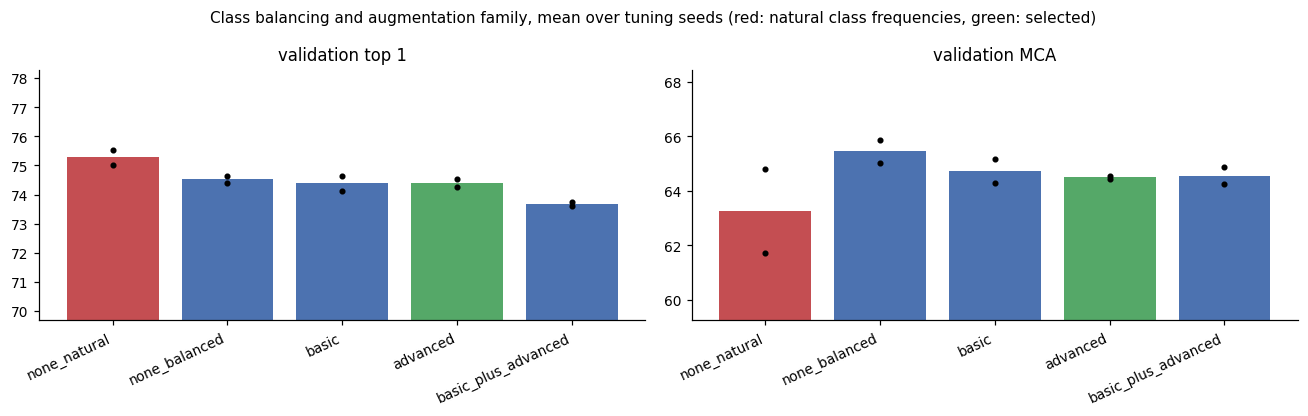

In [7]:
order = list(CONFIGS)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(order))
for ax, metric, title in zip(axes, ["val_top1", "val_mca"], ["validation top 1", "validation MCA"]):
    means = [results.loc[results["config"] == n, metric].mean() for n in order]
    colours = ["#c44e52" if n == "none_natural" else "#55a868" if n == selected else "#4c72b0" for n in order]
    ax.bar(x, 100 * np.array(means), color=colours)
    for i, n in enumerate(order):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["config"] == n, metric], color="black", s=9, zorder=3)
    ax.set_xticks(x, order, rotation=25, ha="right")
    ax.set_ylim(100 * min(means) - 4, 100 * max(means) + 3)
    ax.set_title(title)
fig.suptitle("Class balancing and augmentation family, mean over tuning seeds "
             "(red: natural class frequencies, green: selected)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("balancing and augmentation families", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

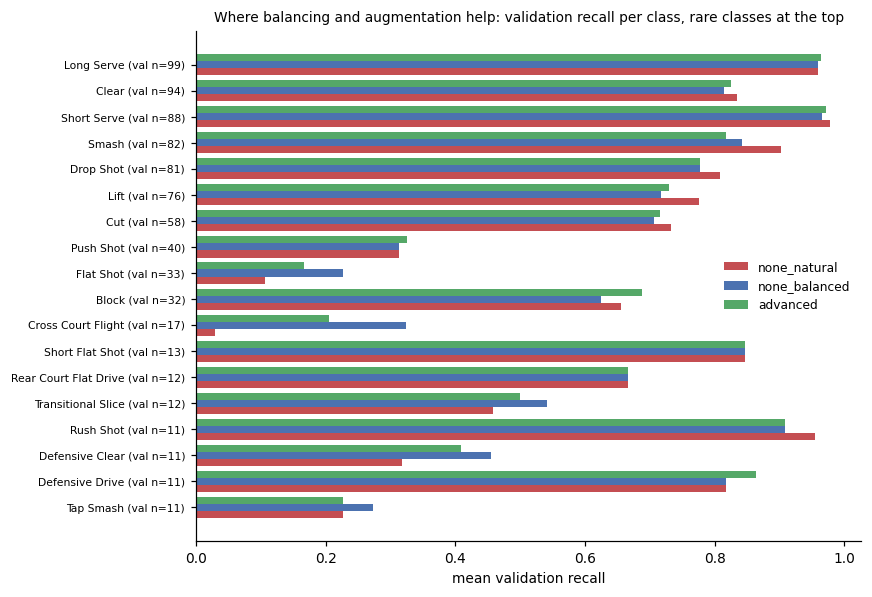

In [8]:
rec = {}
for n in ["none_natural", "none_balanced", selected]:
    frames = []
    for s in SEEDS:
        pc = pd.read_csv(f"{OUT}/stgcn_augfam_{n}_s{s}/stgcn_augfam_{n}_s{s}_per_class.csv")
        frames.append(pc.set_index("class")["recall"])
    rec[n] = pd.concat(frames, axis=1).mean(axis=1)
support = pd.read_csv(f"{OUT}/stgcn_augfam_none_natural_s{SEEDS[0]}/stgcn_augfam_none_natural_s{SEEDS[0]}_per_class.csv").set_index("class")["support"]
recall = pd.DataFrame(rec).assign(support=support).sort_values("support")

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(recall))
for k, (n, c) in enumerate(zip(["none_natural", "none_balanced", selected], ["#c44e52", "#4c72b0", "#55a868"])):
    ax.barh(y + (k - 1) * 0.27, recall[n], height=0.27, color=c, label=n)
ax.set_yticks(y, [f"{c} (val n={s})" for c, s in zip(recall.index, recall["support"])], fontsize=7)
ax.set_xlabel("mean validation recall")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Where balancing and augmentation help: validation recall per class, rare classes at the top", fontsize=9)
fig.tight_layout()
slog.report_matplotlib_figure("per class recall by configuration", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()
slog.report_table("per class validation recall", "val", iteration=0, table_plot=recall.round(3).reset_index())
task.close()

## What to do with the result

- If `none_natural` is far below `none_balanced` and the augmentation rows add little on top, the large
  gains seen in the earlier setup were mostly class balancing, and the honest statement for the thesis is
  that balancing and augmentation are separable contributions and that augmentation's own contribution to top
  1 is small once balancing is in place.
- If `basic` or `basic_plus_advanced` beats `advanced` under the rule, the policy in
  `configs/stgcn_augmentation_families.json` should replace `advanced` in notebooks 06, 09 and 11, which
  then need re-running on the reporting seeds.
- If nothing beats `advanced`, those notebooks stand as reported.